<a href="https://colab.research.google.com/github/SaudAbuhaimid/ML-Practice/blob/main/Titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install catboost
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from sklearn.model_selection import train_test_split, KFold , StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder , OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error
from catboost import CatBoostClassifier
from sklearn.metrics import f1_score
import warnings
warnings.filterwarnings('ignore')





In [ ]:
df = pd.read_csv("train.csv")
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


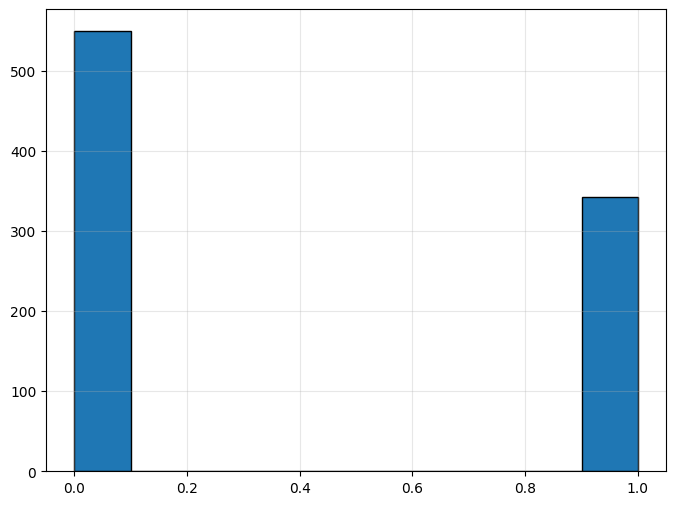

In [ ]:
plt.figure(figsize=(8 , 6))
plt.hist(df['Survived'] , edgecolor='black')
plt.grid(alpha = 0.3)

In [ ]:
# Handle Missing Values
cols_to_drop = ['PassengerId' , 'Cabin' , 'Ticket' , 'Name']
df_clean = df.drop(columns = cols_to_drop)
for col in df_clean:
  if df_clean[col].dtype=='object':
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])
  else:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print(f'The shape before cleaning {df.shape}')
print(f'The shape after cleaning {df_clean.shape}')
missing_val1 = df.isnull().sum().sum()
misi = df_clean.isnull().sum().sum()

print(missing_val1)
print(misi)

The shape before cleaning (891, 12)
The shape after cleaning (891, 8)
866
0


In [ ]:
# Handle and Drop Duplicates:
df_clean = df_clean.drop_duplicates()
df_clean


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
885,0,3,female,39.0,0,5,29.1250,Q
887,1,1,female,19.0,0,0,30.0000,S
888,0,3,female,28.0,1,2,23.4500,S
889,1,1,male,26.0,0,0,30.0000,C


In [ ]:
# Encoding Catagoriecal Features:
le = LabelEncoder()
cols = ['Sex' , 'Embarked']
for col in cols:
  df_clean[col] = le.fit_transform(df_clean[col])
print(df_clean[cols].head())

   Sex  Embarked
0    1         2
1    0         0
2    0         2
3    0         2
4    1         2


In [ ]:
# Scaling the features:
sc = StandardScaler()
X_scaled = sc.fit_transform(df_clean)

In [ ]:
X = pd.DataFrame(X_scaled , columns = df_clean.columns , index = df_clean.index)
y = df_clean['Survived']
X = X.drop(columns = ['Survived' , 'Embarked' , 'Fare'] )

In [ ]:
skf = StratifiedKFold(n_splits=5 , shuffle= True , random_state=42)
f1 = []
model = CatBoostClassifier(iterations=300 , learning_rate=0.1 , depth=6 , random_seed=42 , verbose=0)

for fold , (train_idx , test_idx) in enumerate(skf.split(X , y) , start = 1):

  x_train , x_test = X.iloc[train_idx] , X.iloc[test_idx]
  y_train , y_test = y.iloc[train_idx] , y.iloc[test_idx]

  model.fit(x_train , y_train)
  y_pred = model.predict(x_test)

  f1.append(f1_score(y_test , y_pred))
  print(f'Fold {fold} ==> F1 Score is {f1[-1]:.3f}')

print('-'*30)
print(f'The Average F1 Score is {np.mean(f1):.3f}')

Fold 1 ==> F1 Score is 0.723
Fold 2 ==> F1 Score is 0.762
Fold 3 ==> F1 Score is 0.724
Fold 4 ==> F1 Score is 0.746
Fold 5 ==> F1 Score is 0.679
------------------------------
The Average F1 Score is 0.727


<Axes: >

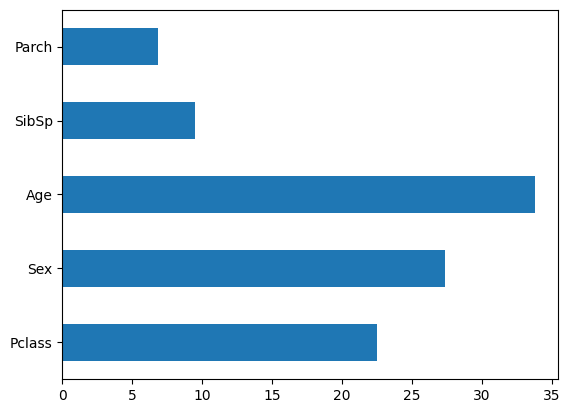

In [ ]:
imp = pd.Series(model.feature_importances_ , index = X.columns)
top = imp.head(15)
top.plot(kind = 'barh')